# 03 - Introducción a la clasificación 2

**Hecho por:** Joshua Sancho

**Correo:** [joshsan1408@gmail.com](mailto:joshsan1408@gmail.com)

**LinkedIn:** [joshsan1408](https://www.linkedin.com/in/joshsan1408/)

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [2]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False})

## 1. Comprensión del problema

Una fila representa una muestra de una masa mamaria. Las **entradas** describen
los núcleos celulares de esa muestra; el **objetivo** es la respuesta que queremos
predecir. Queremos predecir `is_malignant`: si la muestra es maligna (`True`) o
benigna (`False`). Es **clasificación** porque buscamos una categoría.

### Diccionario de datos

Usamos **Breast Cancer Wisconsin (Diagnostic)**. El conjunto cargado contiene
31 columnas: 30 entradas numéricas y la variable objetivo original, `target`.
Más adelante convertiremos esa respuesta a `is_malignant`, con maligna=True y benigna=False.

Las mediciones se obtienen de una imagen digital de una **punción con aguja fina**
de la masa. En una imagen hay varios núcleos celulares: se mide cada núcleo y
se resumen sus mediciones para formar una fila. Un núcleo es la estructura
celular que contiene el material genético.

La tabla describe las diez mediciones. Cada una aparece en tres columnas,
según el resumen utilizado.

| Medición | Qué representa | Qué describe |
| --- | --- | --- |
| `radius` | Promedio de las distancias del centro del núcleo a puntos de su contorno. | Tamaño del núcleo. |
| `texture` | Desviación estándar de la intensidad de los píxeles de la imagen del núcleo. | Cuánto varían sus tonos de gris; no es una textura al tacto. |
| `perimeter` | Longitud del contorno del núcleo. | Tamaño de su borde. |
| `area` | Superficie que ocupa el núcleo en la imagen. | Tamaño de su interior. |
| `smoothness` | Variación local de las longitudes del radio. | Irregularidad local del contorno. |
| `compactness` | `perimeter² / area − 1`. | Relación entre contorno y superficie. |
| `concavity` | Severidad de las partes cóncavas del contorno. | Profundidad de sus entrantes. |
| `concave points` | Número de partes cóncavas del contorno. | Cantidad de entrantes. |
| `symmetry` | Medida de simetría del núcleo. | Semejanza de su forma entre lados. |
| `fractal dimension` | Aproximación de la complejidad del contorno, descrita como «aproximación de costa − 1». | Detalle e irregularidad del borde. |

Los tres resúmenes se calculan **entre los núcleos de una misma imagen**:

| Nombre de columna | Resumen | Ejemplo con radio |
| --- | --- | --- |
| `mean ...` | Media: promedio de las mediciones de los núcleos. | `mean radius`: promedio de los radios medidos en esa muestra. |
| `... error` | Error estándar: estimación de cuánto varía la media entre muestras hipotéticas de núcleos. | `radius error`: error estándar del radio; no es un error del modelo. |
| `worst ...` | Promedio de los tres valores mayores de la medición. | `worst radius`: promedio de los tres radios mayores; no es el máximo único. |

Por ejemplo, si una imagen tuviera radios 10, 12, 14, 16 y 18, su `mean radius`
sería **14** y su `worst radius`, **16**: `(14 + 16 + 18) / 3`.
«Worst» identifica los valores mayores; no es una etiqueta de diagnóstico.

| Variable objetivo | Significado y valores | Función |
| --- | --- | --- |
| `target` | Etiqueta original de scikit-learn: `0` = maligna, `1` = benigna. | Objetivo original; lo retiraremos de las entradas. |
| `is_malignant` | Indicador booleano: `True` = maligna, `False` = benigna. | Objetivo usado en el notebook. |

El ejercicio compara SVM, redes neuronales y XGBoost para identificar muestras
malignas. Importa detectarlas, pero también revisar falsas alarmas. Los resultados
son educativos y no establecen utilidad clínica.

## 2. Comprensión de los datos

### Cargar y revisar

Usamos Breast Cancer Wisconsin (Diagnostic), incluido en scikit-learn.
Conservamos `source_data` sin modificar y trabajamos con una copia.
`head()` muestra las primeras cinco filas para reconocer las columnas y cómo es un registro.

In [3]:
dataset = load_breast_cancer(as_frame=True)
source_data = dataset.frame.copy()
data = source_data.copy()
data.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


`shape` devuelve `(filas, columnas)`. Comprobamos cuántas muestras y campos trae
la fuente antes de estudiar sus relaciones.

In [4]:
print(f"Filas: {data.shape[0]}\nColumnas: {data.shape[1]}")

Filas: 569
Columnas: 31


`info()` muestra el tipo de cada columna y cuántos valores están presentes.
Buscamos tipos inesperados o datos incompletos.

In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

Las entradas aparecen como números y `target`, como entero.
`nunique()` cuenta los valores distintos: una columna con dos valores es **binaria**.

In [6]:
data.nunique()

mean radius                456
mean texture               479
mean perimeter             522
mean area                  539
mean smoothness            474
mean compactness           537
mean concavity             537
mean concave points        542
mean symmetry              432
mean fractal dimension     499
radius error               540
texture error              519
perimeter error            533
area error                 528
smoothness error           547
compactness error          541
concavity error            533
concave points error       507
symmetry error             498
fractal dimension error    545
worst radius               457
worst texture              511
worst perimeter            514
worst area                 544
worst smoothness           411
worst compactness          529
worst concavity            539
worst concave points       492
worst symmetry             500
worst fractal dimension    535
target                       2
dtype: int64

`unique()` muestra los valores distintos de la respuesta original. Comparamos
esos códigos con `target_names` antes de cambiar su significado.

In [7]:
print("Valores de target:", sorted(data["target"].unique()))
print("Nombres originales:", dict(enumerate(dataset.target_names)))

Valores de target: [np.int64(0), np.int64(1)]
Nombres originales: {0: np.str_('malignant'), 1: np.str_('benign')}


La fuente usa `target=0` para maligna y `target=1` para benigna.
Creamos `is_malignant` como **booleano**: `True` indica maligna y `False`, benigna.
La comparación `data["target"] == 0` ya produce ese tipo; no necesita otra conversión.

Para los promedios y las métricas, `True` equivale a 1 y `False`, a 0.
Por eso malignidad sigue siendo la clase positiva. En matrices y gráficos
usaremos también las etiquetas maligna (1) y benigna (0).

Retiramos `target`: es la misma respuesta con otra codificación, no una entrada.
Las 30 mediciones ya son numéricas continuas y conservan ese tipo. Convertirlas
en enteros haría perder decimales; no necesitamos convertirlas en categorías.

In [8]:
data["is_malignant"] = data["target"] == 0
data = data.drop(columns="target")

Comprobamos los tipos resultantes, los faltantes y los valores infinitos por columna.
`isna()` identifica ausentes y `np.isinf()` detecta infinitos, que no son mediciones
válidas para los modelos. Un cero indica que no encontramos ese problema.

In [9]:
pd.DataFrame({
    "DType": data.dtypes,
    "Null": data.isna().sum(),
    "Infinitos": np.isinf(data).sum(),
})

,DType,Null,Infinitos
mean radius,float64,0,0
mean texture,float64,0,0
mean perimeter,float64,0,0
mean area,float64,0,0
mean smoothness,float64,0,0
mean compactness,float64,0,0
mean concavity,float64,0,0
mean concave points,float64,0,0
mean symmetry,float64,0,0
mean fractal dimension,float64,0,0


No hay datos ausentes ni infinitos en esta versión. No necesitamos completar
valores con una estimación. Antes de dividir, comprobamos si hay filas repetidas.
La versión cargada no incluye identificadores para revisar repeticiones por paciente.

In [10]:
print(f"Duplicados exactos: {data.duplicated().sum()}")
print(f"Mediciones repetidas: {data.drop(columns='is_malignant').duplicated().sum()}")

Duplicados exactos: 0
Mediciones repetidas: 0


### Separar entradas y objetivo

- **`X`:** las 30 características que recibe el modelo, como `mean radius` y `mean texture`.
- **`y`:** la respuesta que queremos predecir, `is_malignant`.

No hay una columna de identificación en la versión cargada. Conservamos el índice
para localizar cada muestra y agrupamos las entradas según su tipo.

In [11]:
target_col = "is_malignant"
X = data.drop(columns=target_col)
y = data[target_col]

In [12]:
numeric_features = X.select_dtypes("number").columns.tolist()

### Separar entrenamiento y prueba

Reservamos **70% para entrenamiento** y **30% para prueba**:

- **Entrenamiento:** datos con los que aprende el modelo.
- **Validación:** partes del entrenamiento que usaremos para comparar opciones.
- **Prueba:** datos reservados para evaluar al final, después de elegir el modelo.

`stratify=y` conserva proporciones parecidas de malignidad en ambas partes.
`random_state=42` permite repetir el mismo reparto. Conservamos los índices para
mantener cada muestra junto a su respuesta.

Desde aquí exploramos **solo entrenamiento**. Esta exploración se conoce como EDA.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42,
)
train = X_train.join(y_train)
print(f"Entrenamiento: {len(X_train)}; prueba reservada: {len(X_test)}")

Entrenamiento: 398; prueba reservada: 171


### ¿Cuántas muestras son benignas y cuántas malignas?

Comparamos cantidad y porcentaje de cada clase en entrenamiento.

In [14]:
class_balance = y_train.value_counts().sort_index().to_frame("Muestras")
class_balance["Porcentaje"] = class_balance["Muestras"].div(len(y_train)).mul(100).round(2)
class_balance.round(2)

,Muestras,Porcentaje
is_malignant,,
False,250,62.81
True,148,37.19


Hay 250 muestras benignas y 148 malignas: aproximadamente 62,8% y 37,2%.
Las clases están desbalanceadas: tenemos más ejemplos de muestras benignas.

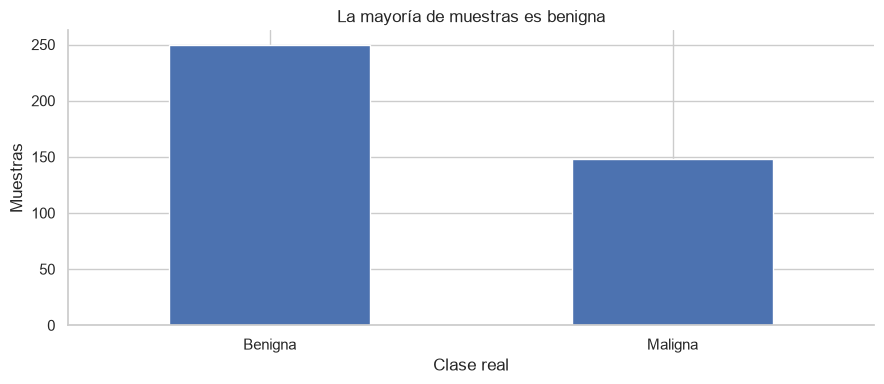

In [15]:
ax = class_balance["Muestras"].rename(index={0: "Benigna", 1: "Maligna"}).plot.bar(rot=0)
ax.set(xlabel="Clase real", ylabel="Muestras", title="La mayoría de muestras es benigna")
plt.tight_layout()
plt.show()

### Desbalance de clases: ¿hay que corregirlo?

Hay más muestras benignas que malignas. Esto puede ser natural:
**no necesitamos forzar una distribución 50/50**.

El problema aparece si el modelo aprende a predecir casi siempre benigna.
Esa regla acertaría en el 62,8% de entrenamiento, pero no detectaría ninguna
maligna. Por eso revisaremos también las malignas detectadas.

#### Opciones para entrenar

| Opción | Qué hace | Qué debemos cuidar |
| --- | --- | --- |
| Conservar los datos | Entrena con la distribución original. | Es un punto de partida válido. |
| Undersampling | Quita al azar ejemplos de la clase mayoritaria. | Puede perder información útil. |
| Oversampling | Repite ejemplos de la clase minoritaria. | No añade información nueva y puede favorecer la memorización. |
| SMOTE | Crea ejemplos artificiales combinando valores de vecinos. | Las mediciones creadas pueden no representar una muestra real. |
| Pesos de clase | Da más importancia a los errores de una clase al entrenar. | Puede detectar más malignas y también generar más falsas alarmas. |

Aquí conservamos las filas y los pesos por defecto. Comparamos modelos y sus
hiperparámetros; no hemos comparado técnicas de remuestreo o pesos de clase.
Si probáramos remuestreo, se aplicaría solo a los datos con los que aprende el
modelo en cada ronda; validación y prueba conservarían su distribución original.

### ¿Cómo se distribuyen las mediciones de cada muestra?

Exploramos **radio medio y área media** para describir tamaño, **textura media**
para describir la variación de tonos y **suavidad media y puntos cóncavos medios**
para describir el contorno. Son aspectos distintos de la imagen, no una selección
automática de las variables más importantes. Conservaremos las 30 entradas al modelar.

Las columnas `mean ...` ya contienen un promedio de los núcleos de **una imagen**.
Al calcular su media o mediana en el EDA, resumimos esos valores **entre muestras**.
Por ejemplo, la mediana de `mean area` es la mediana de las áreas medias de las imágenes.

`describe()` resume las 30 entradas numéricas, incluidos los resúmenes `mean`,
`error` y `worst`:

- `count`: datos presentes; `mean`: promedio; `std`: cuánto varían los valores.
- `min` y `max`: extremos; `50%`: mediana, el valor central al ordenar los datos.
- `25%` y `75%`: valores por debajo de los que está el 25% y el 75% de los datos.

`.T` coloca una variable por fila y `.round(3)` permite leer también mediciones pequeñas.

In [16]:
train[numeric_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
mean radius,398.0,14.127,3.553,6.981,11.672,13.355,15.832,28.110
mean texture,398.0,19.438,4.322,9.710,16.330,19.030,21.862,39.280
mean perimeter,398.0,91.904,24.448,43.790,75.008,86.365,104.175,188.500
mean area,398.0,655.325,353.683,143.500,416.450,548.750,790.575,2499.000
mean smoothness,398.0,0.096,0.014,0.063,0.085,0.095,0.105,0.163
mean compactness,398.0,0.103,0.053,0.019,0.063,0.091,0.130,0.345
mean concavity,398.0,0.088,0.081,0.000,0.030,0.060,0.132,0.427
mean concave points,398.0,0.049,0.039,0.000,0.020,0.033,0.071,0.201
mean symmetry,398.0,0.181,0.027,0.106,0.162,0.180,0.195,0.291
mean fractal dimension,398.0,0.063,0.007,0.050,0.057,0.061,0.066,0.097


### Asimetría: revisión rápida con `.skew()`

`skew()` resume la **asimetría** de cada entrada numérica:

- **Positivo:** cola hacia los valores altos, a la derecha.
- **Negativo:** cola hacia los valores bajos, a la izquierda.
- **Cercano a cero:** poca asimetría según esta medida; no demuestra normalidad.

Usamos solo entrenamiento y excluimos el objetivo con `numeric_features`.
Ordenamos de mayor a menor y mostramos dos decimales. Los resultados no son porcentajes.

In [ ]:
train[numeric_features].skew().sort_values(ascending=False).round(2)

concavity error            5.39
area error                 4.76
fractal dimension error    4.24
perimeter error            3.33
radius error               2.92
smoothness error           2.57
symmetry error             2.34
texture error              1.82
worst fractal dimension    1.82
compactness error          1.79
worst area                 1.74
mean area                  1.64
concave points error       1.61
worst symmetry             1.58
worst compactness          1.49
mean concavity             1.48
mean fractal dimension     1.32
mean compactness           1.31
mean concave points        1.22
worst concavity            1.15
worst perimeter            1.09
worst radius               1.08
mean perimeter             1.00
mean radius                0.96
mean symmetry              0.69
mean texture               0.65
mean smoothness            0.60
worst texture              0.49
worst concave points       0.47
worst smoothness           0.43
dtype: float64

Todas las entradas tienen asimetría positiva en este entrenamiento.
Las mayores son **`concavity error` (5,39)**, **`area error` (4,76)** y
**`fractal dimension error` (4,24)**: sus colas se extienden hacia valores altos.
`mean area` también presenta asimetría positiva (**1,64**), coherente con la
media mayor que la mediana en la tabla de `describe()`.

`worst smoothness` (**0,43**) está más cerca de cero que las anteriores, aunque
eso no demuestra una distribución normal. La asimetría no convierte los valores
extremos en errores ni obliga a eliminarlos o transformar las entradas.
`StandardScaler` ajusta la escala, pero no elimina la asimetría.
Conservamos las mediciones y continuamos con las comparaciones entre clases.

La mediana de `mean radius` es 13,36 entre las muestras de entrenamiento.
En `mean area`, la media entre muestras (655,33) supera a la mediana entre muestras
(548,75): algunas imágenes con áreas medias altas elevan el promedio.

Un **histograma** cuenta muestras por intervalos; `bins` indica cuántos intervalos usar.

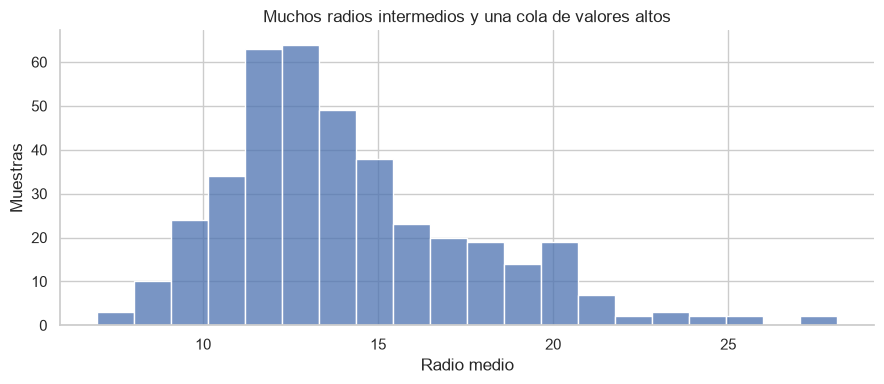

In [17]:
fig, ax = plt.subplots()
sns.histplot(data=train, x="mean radius", bins=20, ax=ax)
ax.set(xlabel="Radio medio", ylabel="Muestras", title="Muchos radios intermedios y una cola de valores altos")
plt.tight_layout()
plt.show()

Los valores de `mean radius` se concentran en la zona intermedia y se extienden
hacia valores altos. Veamos si `mean texture`, la textura media de cada imagen,
se distribuye de la misma manera.

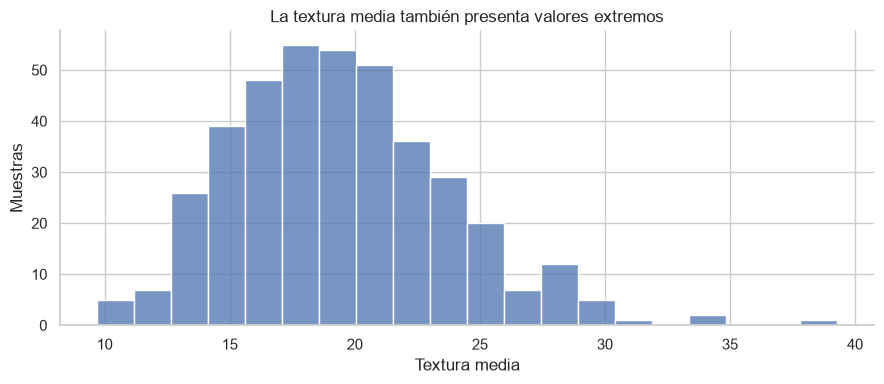

In [18]:
fig, ax = plt.subplots()
sns.histplot(data=train, x="mean texture", bins=20, ax=ax)
ax.set(xlabel="Textura media", ylabel="Muestras", title="La textura media también presenta valores extremos")
plt.tight_layout()
plt.show()

La textura media va de 9,71 a 39,28 en entrenamiento. Un valor alto no es
automáticamente un error: conservamos los extremos. Ahora pasamos de describir
entradas a relacionarlas con la clase de la muestra.

### ¿Cambia el porcentaje de malignas según el radio medio?

`cut()` agrupa el radio medio en intervalos. `assign()` añade esa agrupación a
una copia para explorar; el modelo seguirá recibiendo las mediciones originales.
Los límites son grupos exploratorios, no umbrales de diagnóstico.

`groupby()` reúne muestras del mismo rango y `agg()` calcula un resumen.
`size` cuenta muestras y `mean` promedia `is_malignant`. Como `False` equivale a 0 y `True`, a 1,
ese promedio es la **proporción de malignas**: 0,40 significa que lo es el 40%.
`observed=True` muestra solo categorías presentes en los datos.

Multiplicamos **solo esa proporción** por 100 con `.mul(100)` y mostramos dos
decimales con `.round(2)`. Así, 0,40 se muestra como **40,00%**.
`Muestras` conserva el conteo original; no lo multiplicamos.

In [19]:
radius_groups = train.assign(radius_range=pd.cut(
    train["mean radius"], bins=[0, 12, 15, 18, float("inf")], right=False,
    labels=["<12", "12–<15", "15–<18", "18+"],
))
radius_summary = radius_groups.groupby("radius_range", observed=True)[target_col].agg(
    Muestras="size", Porcentaje="mean",
)
radius_summary["Porcentaje"] = radius_summary["Porcentaje"].mul(100).round(2)
radius_summary

,Muestras,Porcentaje
radius_range,,
<12,120,5.00
12–<15,157,18.47
15–<18,60,86.67
18+,61,100.00


La proporción de malignas pasa de 5,0% en radios medios menores a 12 a 100% en 18 o más.
Los grupos tienen tamaños distintos; comparamos proporciones, no solo cantidades.

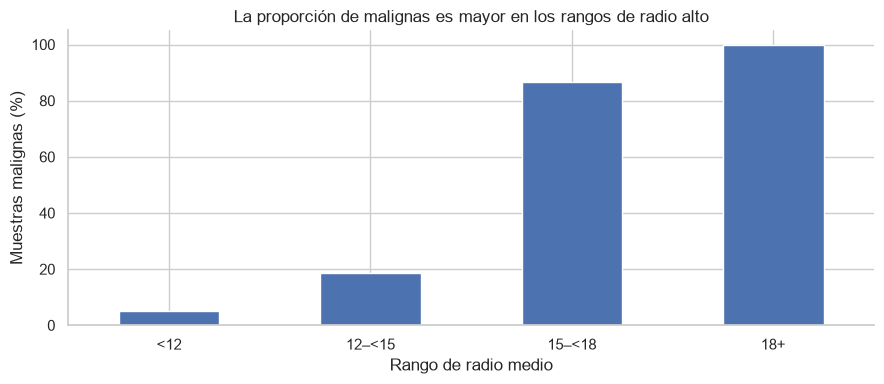

In [20]:
ax = radius_summary["Porcentaje"].plot.bar(rot=0)
ax.set(xlabel="Rango de radio medio", ylabel="Muestras malignas (%)", ylim=(0, 105),
       title="La proporción de malignas es mayor en los rangos de radio alto")
plt.tight_layout()
plt.show()

Esta diferencia es una asociación: no demuestra que aumentar el radio medio cause
malignidad. El 100% describe estas 61 muestras, no garantiza el resultado de
futuras muestras. Revisemos otra característica que podría distinguir los grupos.

### ¿Cambia el porcentaje de malignas según la textura media?

`cut()` agrupa `mean texture` en intervalos. Conservamos también `radius_range`,
creado desde `mean radius`, para cruzar ambas mediciones. Estos rangos se usan
solo en el EDA.

In [21]:
texture_groups = radius_groups.assign(texture_range=pd.cut(
    radius_groups["mean texture"], bins=[0, 15, 20, 25, float("inf")], right=False,
    labels=["<15", "15–<20", "20–<25", "25+"],
))
texture_summary = texture_groups.groupby("texture_range", observed=True)[target_col].agg(
    Muestras="size", Porcentaje="mean",
)
texture_summary["Porcentaje"] = texture_summary["Porcentaje"].mul(100).round(2)
texture_summary

,Muestras,Porcentaje
texture_range,,
<15,56,3.57
15–<20,176,26.14
20–<25,125,62.40
25+,41,53.66


La proporción sube de 3,6% en textura media menor a 15 a 62,4% en `20–<25`,
pero baja a 53,7% en `25+`: no crece en todos los intervalos.
¿La diferencia por radio medio se mantiene al comparar texturas medias parecidas?
`pivot_table()` organiza las proporciones por rango de textura media y radio medio.
Cada casilla se convierte con `.mul(100).round(2)`: **7,59** significa **7,59%**
de malignas dentro de esa combinación, no 7,59 muestras.

In [22]:
texture_groups.pivot_table(
    index="texture_range", columns="radius_range", values=target_col,
    aggfunc="mean", observed=True,
).mul(100).round(2)

radius_range,<12,12–<15,15–<18,18+
texture_range,,,,
<15,0.00,0.00,33.33,NaN
15–<20,7.02,7.59,77.78,100.0
20–<25,7.41,48.84,100.00,100.0
25+,0.00,15.38,100.00,100.0


En textura media `15–<20`, la proporción pasa de 7,0% en radio medio menor a 12 a 100%
en radio medio de 18 o más. `NaN` indica que no hay muestras en esa combinación,
no una proporción de cero. `crosstab()` muestra cuántas muestras sostienen cada comparación.

In [23]:
pd.crosstab(texture_groups["texture_range"], texture_groups["radius_range"])

radius_range,<12,12–<15,15–<18,18+
texture_range,,,,
<15,28,22,6,0
15–<20,57,79,18,22
20–<25,27,43,26,29
25+,8,13,10,10


En textura media menor a 15 hay solo seis muestras con radio medio `15–<18`, y ninguna
con radio medio de 18 o más. Las proporciones de grupos pequeños cambian mucho con
pocas muestras: conviene leer cantidades y proporciones juntas.

### ¿El área media de los núcleos es distinta entre clases?

Agrupamos las muestras por diagnóstico y resumimos `mean area`, el área media
de los núcleos de cada imagen:

- **Muestras:** cuántas imágenes hay en cada clase.
- **Media:** promedio de sus valores de `mean area`.
- **Mediana:** valor central de sus valores de `mean area` al ordenarlos.

La mediana de esta tabla se calcula entre imágenes; no es la mediana del área
de los núcleos dentro de una imagen.

In [24]:
train.groupby(target_col)["mean area"].agg(Muestras="size", Media="mean", Mediana="median").round(2)

,Muestras,Media,Mediana
is_malignant,,,
False,250,464.14,460.65
True,148,978.28,932.00


La mediana de `mean area` es **460,65 en muestras benignas** y **932,00 en malignas**.
Es decir, comparamos el valor central de las **áreas medias por imagen** de cada clase.
La diferencia entre medianas no implica que todos los valores de una clase
sean mayores que todos los de la otra.

### ¿La suavidad media y los puntos cóncavos medios cambian entre clases?

Repetimos la agrupación con `mean smoothness` y `mean concave points`.
Cada columna ya resume los núcleos de una imagen. Ahora calculamos cantidad,
media y mediana de esos valores entre las muestras de cada diagnóstico.
Sus números son mucho menores que los de `mean area`: tienen escalas distintas.

In [25]:
train.groupby(target_col)[["mean smoothness", "mean concave points"]].agg(
    ["count", "mean", "median"],
).round(3)

mean smoothness               mean concave points              
                       count   mean median               count   mean median
is_malignant                                                                
False                    250  0.092  0.090                 250  0.025  0.023
True                     148  0.103  0.101                 148  0.088  0.086

La mediana de `mean smoothness` es aproximadamente **0,090 en muestras benignas**
y **0,101 en malignas**. La de `mean concave points` es **0,023 frente a 0,086**.
Ambas medianas se calculan entre imágenes, usando el valor medio que trae cada fila.

Las diferencias describen grupos: no convierten una medición aislada en una regla
de diagnóstico. Una diferencia numérica pequeña tampoco significa poca importancia:
las escalas difieren.

### ¿El radio medio y la textura media son distintos entre clases?

Comparamos media y mediana de `mean radius` y `mean texture` entre las muestras
de cada clase. `count` permite ver cuántas imágenes tienen un valor presente
en cada columna.

In [26]:
train.groupby(target_col)[["mean radius", "mean texture"]].agg(["count", "mean", "median"]).round(2)

mean radius               mean texture              
                   count   mean median        count   mean median
is_malignant                                                     
False                250  12.15  12.22          250  18.16  17.70
True                 148  17.46  17.33          148  21.60  21.44

En malignas, la mediana de `mean radius` es mayor: **17,33 frente a 12,22**
en benignas. También lo es la mediana de `mean texture`: **21,45 frente a 17,70**.
Son medianas entre muestras de los valores medios de cada imagen.

En el **boxplot**, cada observación es el `mean radius` de una muestra.
La línea central es su mediana y la caja contiene el 50% central de esos valores.
Los puntos fuera de los bigotes son posibles extremos, no necesariamente errores.

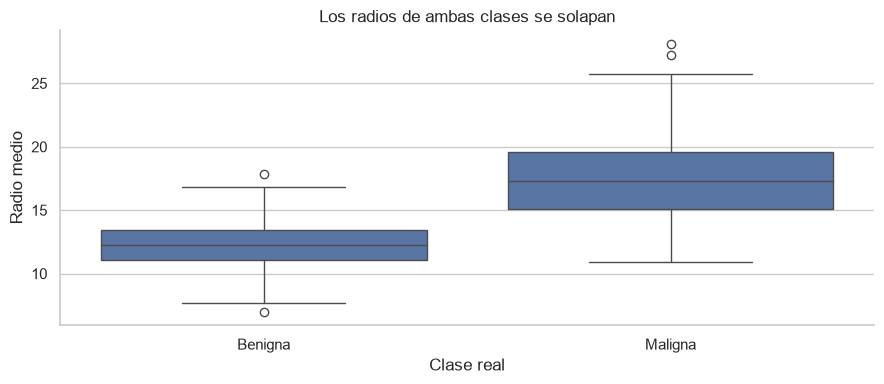

In [27]:
fig, ax = plt.subplots()
sns.boxplot(data=train, x=target_col, y="mean radius", ax=ax)
ax.set(xticks=[0, 1], xticklabels=["Benigna", "Maligna"],
       xlabel="Clase real", ylabel="Radio medio", title="Los radios de ambas clases se solapan")
plt.tight_layout()
plt.show()

Aunque las medianas difieren, algunos valores de `mean radius` aparecen en ambas
clases: una entrada no separa perfectamente las muestras.
¿Los puntos cóncavos medios cambian entre clases dentro de rangos de radio medio parecidos?

`pivot_table()` coloca los rangos de `mean radius` en filas y las clases en columnas.
`values="mean concave points"` elige la medición que resumimos;
`aggfunc="median"` calcula su mediana entre las muestras de cada combinación.
Son medianas de una medición, no porcentajes de malignidad como en la tabla anterior.
Por eso aquí no multiplicamos por 100.

In [28]:
radius_groups.pivot_table(
    index="radius_range", columns=target_col, values="mean concave points",
    aggfunc="median", observed=True,
).rename(columns={0: "Benigna", 1: "Maligna"}).round(3)

is_malignant,Benigna,Maligna
radius_range,,
<12,0.019,0.060
12–<15,0.026,0.069
15–<18,0.045,0.077
18+,NaN,0.098


Entre las muestras con `mean radius` en `12–<15`, la mediana de
`mean concave points` es **0,026 en benignas** y **0,069 en malignas**.
La diferencia en los puntos cóncavos medios no desaparece al comparar radios medios parecidos.
En `18+` no hay muestras benignas en entrenamiento; `NaN` indica ausencia de muestras,
no una mediana de cero. Sus cantidades se revisaron antes con `crosstab()`.

### ¿Qué nos llevamos al modelado?

- La clase maligna es minoritaria: acertar muchas benignas no basta.
- Radio medio y textura media muestran diferencias entre clases, también al cruzarlos.
- Los puntos cóncavos medios aportan otra comparación, incluso dentro de rangos de radio medio.
- Las escalas difieren y hay solapamiento: una medición no separa perfectamente ambas clases.

Conservamos las 30 entradas preparadas antes de dividir. Los rangos se
usaron para explorar, no como nuevas variables del modelo.

## 3. Preparación de los datos

Los modelos necesitan entradas numéricas. `ColumnTransformer` permite preparar
cada grupo de columnas de forma distinta.

### Entradas: conservar las mediciones numéricas

Aquí las 30 entradas ya son números. No hay categorías que convertir con
`OneHotEncoder` ni columnas booleanas que preparar por separado.
Conservamos `numeric_features`, la lista de mediciones definida desde `X`.

### Numéricos: ajustar las escalas

#### ¿Qué hacemos con un dato ausente?

**Imputar** es reemplazarlo por una estimación, como la mediana aprendida en
entrenamiento. En este conjunto no hay faltantes: no necesitamos imputar.
No añadimos un paso que no transforma estos datos.

#### Escalar las mediciones

**Escalar** pone las variables en escalas comparables. `StandardScaler` resta
la media y divide por la desviación estándar, una medida de cuánto varían los valores.
Lo usamos en SVM y redes neuronales: sin escalar, el área media podría dominar las
distancias solo porque sus números son mayores.

Por ejemplo, un valor dos desviaciones por encima de su media queda cerca de 2.
Escalar no convierte una distribución en normal ni elimina valores extremos.
Las medias y escalas se calculan solo con los datos usados para aprender.

### Seleccionar las columnas que vamos a preparar

El paso `numeric` aplica el escalado a las 30 columnas de `numeric_features`.
El objetivo queda fuera porque la lista se obtuvo desde `X`, no desde `data`.

In [29]:
scaled_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
])

### Preparación para XGBoost

Los árboles hacen preguntas como «¿radio medio menor a un valor?». No calculan
distancias entre muestras, por lo que aquí no necesitan escalado.
`passthrough` conserva las mediciones originales.

In [30]:
unscaled_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", numeric_features),
])

Un **pipeline** encadena preparación y modelo:

- `fit`: aprende cómo escalar y clasificar.
- `predict`: aplica lo aprendido para predecir nuevas filas.

Aprender transformaciones con datos de validación o prueba daría pistas sobre
la evaluación: eso es **fuga de información** (*data leakage*). El pipeline ayuda
a evitarla, porque en cada ajuste aprende todos los pasos solo con entrenamiento.

In [ ]:
pipeline = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", CalibratedClassifierCV(SVC(kernel="linear", random_state=42),
                                     cv=3, ensemble=False)),
])

## 4. Modelado

### SVM lineal: separar clases dejando un margen

Imaginemos dos grupos de puntos. Colocamos **dos líneas paralelas**, una junto
a cada grupo, e intentamos dejar entre ellas el pasillo más ancho posible.
La línea que queda en medio es la **frontera de decisión**: decide de qué lado
clasificamos una muestra. Ese pasillo es el **margen**.

Una **máquina de vectores de soporte (SVM)** busca ese margen. Los puntos que
determinan sus límites se llaman **vectores de soporte**. Si los grupos se
solapan, admite algunos errores; no siempre podemos separarlos perfectamente.
En el dibujo hay dos entradas; con 30, la idea de la frontera se mantiene,
aunque ya no podamos dibujar todas las dimensiones.

#### ¿Qué es un kernel?

Un **kernel** es una regla matemática para **comparar dos muestras a partir de
sus entradas**. Devuelve un valor que expresa su similitud según esa regla.
SVM utiliza esas comparaciones para aprender la frontera entre las clases.
El kernel no decide por sí solo si una muestra es maligna o benigna.

Cambiar el kernel cambia la forma de comparar las muestras y las fronteras que
SVM puede aprender:

| Kernel | Idea sencilla | Frontera que permite |
| --- | --- | --- |
| `linear` | Compara las muestras mediante una combinación de sus mediciones originales. | Una recta en un dibujo con dos entradas. |
| `rbf` | Da mayor similitud a muestras cercanas y menor a muestras lejanas. | Fronteras curvas, como veremos en la siguiente imagen. |

Por ejemplo, con RBF, dos muestras con mediciones escaladas muy parecidas reciben
una similitud alta. Si sus mediciones son muy distintas, la similitud baja.
Esa comparación utiliza las entradas; las etiquetas sirven para aprender qué
separación distingue las clases.

Aquí empezamos con `kernel="linear"`, que mantiene una frontera lineal en las entradas escaladas.
`C` controla cuánto penalizamos los errores: un valor mayor intenta evitarlos
con más fuerza y puede sobreajustar. La búsqueda podrá elegir `C=0.01`, `0.1`, `1`, `10` o `100`.

SVC produce un puntaje de separación. `CalibratedClassifierCV` aprende a
convertirlo en una probabilidad usando tres bloques internos (`cv=3`).
`ensemble=False` conserva un SVC reajustado y su calibrador. Así podemos usar
`predict_proba()` y el corte 0,50, como con los modelos del día anterior.

<img src="https://upload.wikimedia.org/wikipedia/commons/7/72/SVM_margin.png" alt="Dos clases separadas por una frontera central roja y dos líneas discontinuas que delimitan el margen; los puntos rodeados son vectores de soporte." width="520" style="background-color: white;">

La línea roja decide la clase y las discontinuas delimitan el margen. Los puntos
rodeados son vectores de soporte; para seguir la idea basta con observar las líneas.
Fuente: [Larhmam — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:SVM_margin.png),
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).

In [32]:
linear_svm_model = CalibratedClassifierCV(
    SVC(kernel="linear", random_state=42), cv=3, ensemble=False,
)

### SVM con RBF: el kernel y el truco de cambiar la representación

Ahora cambiamos la regla de comparación. Si un grupo está rodeado por otro,
una recta no puede separarlos en el dibujo
original. Una idea es añadir otra forma de describir los puntos: por ejemplo,
su distancia al centro. En esa nueva representación, los grupos pueden quedar
a distintas alturas y resultar más fáciles de separar.

El **truco del kernel** permite trabajar como si hubiéramos cambiado a una
representación con más dimensiones, calculando similitudes sin construir
explícitamente todas esas nuevas columnas. Al mirar la separación desde el
espacio original, la frontera puede verse curva.

**RBF** es un kernel que da mayor similitud a muestras cercanas y menor a las
lejanas. Por eso escalamos las mediciones antes de compararlas. La imagen usa
una altura basada en la distancia para ilustrar la idea; RBF no crea literalmente
solo esa columna.

`gamma` controla el alcance de cada muestra. Un valor grande concentra su
influencia en una región pequeña y puede crear una frontera demasiado local.
`gamma="scale"` usa una regla basada en la variación de las entradas de ese ajuste.
La búsqueda podrá elegir `C=0.1`, `1`, `10` o `100`, con
`gamma="scale"`, `0.001`, `0.01` o `0.1`.

Una frontera más flexible puede **sobreajustar**: ajustarse mucho a entrenamiento
y fallar con muestras nuevas. La validación dirá si la flexibilidad ayuda.

<img src="https://upload.wikimedia.org/wikipedia/commons/c/cc/Kernel_trick_idea.svg" alt="A la izquierda, una frontera circular separa dos grupos; a la derecha, una dimensión adicional permite separarlos con una superficie plana." width="800" style="background-color: white;">

Izquierda: el grupo central está rodeado por el otro. Derecha: una medida adicional
permite separarlos con una superficie plana. Ilustra el cambio de representación;
no es una transformación RBF exacta.
Fuente: [Shiyu Ji — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Kernel_trick_idea.svg),
[CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/).

In [33]:
rbf_svm_model = CalibratedClassifierCV(
    SVC(kernel="rbf", random_state=42), cv=3, ensemble=False,
)

### Red neuronal: combinar entradas con pesos y bias

Una red neuronal **multicapa (MLP)** conecta pequeñas unidades llamadas **neuronas**.
Cada neurona empieza con una operación parecida a la regresión lineal del día 1:

`combinación = entrada 1 × peso 1 + entrada 2 × peso 2 + ... + bias`

- **Peso:** multiplica una entrada y regula cuánto influye en esa combinación.
  Puede ser positivo o negativo. En el dibujo, cada conexión lleva un peso.
- **Bias o sesgo:** es un valor que se suma, como el **intercepto** de la regresión
  lineal. Permite desplazar la respuesta aunque las entradas sean cero.

<img src="https://upload.wikimedia.org/wikipedia/commons/6/6a/Perceptron-unit.svg" alt="Una neurona recibe entradas multiplicadas por sus pesos, añade el bias mediante una entrada constante, suma los resultados y aplica una activación." width="520" style="background-color: white;">

En el esquema, `x` son entradas y `w`, pesos. La entrada constante `x₀=1` hace
que `w₀` actúe como el **bias**. `Σ` suma las contribuciones, `φ` aplica la activación
y `o` es la salida. No hace falta desarrollar las fórmulas para seguir el recorrido.
Fuente: [MartinThoma — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Perceptron-unit.svg),
[CC0](https://creativecommons.org/publicdomain/zero/1.0/).

Después, la neurona aplica una **activación**, una regla que transforma esa
combinación. Usamos **ReLU**: deja pasar los valores positivos y convierte los
negativos en cero. Esa transformación permite aprender algo más flexible que
una única combinación lineal.

Una capa entrega sus resultados a la siguiente. Las capas ocultas aprenden
combinaciones de las mediciones y la salida binaria estima una probabilidad.
Al entrenar, la red compara sus predicciones con las etiquetas y **ajusta pesos
y bias** para reducir los errores. No le decimos qué debe detectar cada neurona.

`hidden_layer_sizes=(16,)` crea una capa oculta de 16 neuronas.
La búsqueda podrá elegir `(8,)`, `(16,)`, `(32,)` o `(32, 16)`.
La última opción crea dos capas: 32 y después 16. Las 30 entradas y la salida no se
incluyen en esa tupla. **Adam** es el método que actualiza los parámetros;
una **época** es un recorrido por los datos de entrenamiento.

`alpha` penaliza pesos grandes; un valor mayor regulariza más.
La búsqueda podrá elegir `alpha=0.0001`, `0.001`, `0.01` o `0.1`. `max_iter=2000` limita las épocas, pero el ajuste
puede terminar antes. Si aparece `ConvergenceWarning`, revisamos el ajuste con
entrenamiento; no usamos la prueba para decidir cómo cambiarlo.

<img src="https://upload.wikimedia.org/wikipedia/commons/e/e4/Artificial_neural_network.svg" alt="Red neuronal con capa de entrada, una capa oculta y una capa de salida, conectadas mediante flechas." width="450" style="background-color: white;">

`Input`, `Hidden` y `Output` indican entrada, capa oculta y salida. Cada flecha
lleva un peso. La imagen muestra una red genérica con dos salidas; nuestra red
binaria tiene 30 entradas y una salida que estima la probabilidad de malignidad.
Fuente: [Cburnett — Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Artificial_neural_network.svg),
[CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/).

In [34]:
neural_model = MLPClassifier(
    activation="relu", solver="adam", max_iter=2000, random_state=42,
)

### XGBoost: nuevos árboles que mejoran el resultado acumulado

Primero entrenamos un árbol pequeño. Miramos dónde falla el conjunto y entrenamos
otro árbol para aportar una **corrección**. Después añadimos otro, y repetimos.
Así, lo aprendido hasta ahora orienta qué necesita mejorar el siguiente paso.

**El resultado final combina los árboles anteriores y las nuevas correcciones.**
No sustituimos simplemente el primer árbol por el último. En clasificación,
«corregir» significa mejorar las estimaciones para acercarlas a las etiquetas,
no copiar sin más las muestras que se clasificaron mal.

Este proceso se llama **boosting**. XGBoost usa **gradient boosting**: calcula
una dirección para reducir el error y entrena cada nuevo árbol para aportar
una corrección en esa dirección. No necesitamos desarrollar esa matemática
para seguir el ejemplo.

Un bosque aleatorio entrena árboles con distintas muestras y combina sus votos.
En XGBoost, los árboles se añaden en secuencia para mejorar el resultado acumulado.

`n_estimators` indica cuántos árboles crear: la búsqueda podrá elegir 50, 100, 150 o 200.
`max_depth` limita los niveles de preguntas por árbol: podrá elegir 1, 2, 3 o 4.
`learning_rate=0.05` hace que cada corrección tenga un aporte pequeño.
Más árboles o mayor profundidad pueden sobreajustar, incluso con pasos pequeños.

`objective="binary:logistic"` configura la clasificación binaria.
`eval_metric="logloss"` es una métrica interna; la búsqueda elegirá por recall.
`n_jobs=1` limita los hilos por ajuste y `tree_method="hist"` busca divisiones
agrupando los valores en intervalos.

<img src="https://raw.githubusercontent.com/dmlc/web-data/master/xgboost/model/twocart.png" alt="Dos árboles asignan puntuaciones a los mismos ejemplos y sus aportes se suman para obtener la puntuación del conjunto." width="800" style="background-color: white;">

Cada árbol aporta una puntuación. Para el niño del ejemplo, los aportes se suman:
`2 + 0,9 = 2,9`. Son puntuaciones, no probabilidades. La imagen muestra cómo se
combinan los árboles; durante boosting, cada nuevo árbol busca mejorar el resultado
acumulado de los anteriores.
Fuente: [XGBoost — Introduction to Boosted Trees](https://xgboost.readthedocs.io/en/stable/tutorials/model.html#decision-tree-ensembles).

In [35]:
xgb_model = XGBClassifier(
    objective="binary:logistic", eval_metric="logloss", tree_method="hist",
    learning_rate=0.05, reg_lambda=1, random_state=42, n_jobs=1,
)

### Baseline: una referencia sencilla

Un **baseline** permite preguntar si el modelo mejora una regla simple.
`DummyClassifier(strategy="most_frequent")` aprende la clase más frecuente
en entrenamiento y la repite para todos: aquí siempre predice benigna.

In [36]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train);

### ¿Cómo elegimos entre modelos?

- **Recall:** de las muestras malignas, ¿a cuántas detectamos?
- **Precisión:** de las muestras que señalamos, ¿cuántas son malignas?

Si señalamos 10 muestras y 6 son malignas, la precisión es 6/10 = **60%**.
Si había 8 malignas en total, el recall es 6/8 = **75%**.

Elegimos por **recall de validación** porque, en este ejercicio, queremos priorizar
que no queden malignas sin identificar. Un falso negativo es una maligna que
clasificamos como benigna; un falso positivo es una benigna que señalamos.

Recall solo tampoco basta: **predecir todas como malignas daría recall de 100%**,
pero señalaría también todas las benignas. Por eso revisamos precisión y balanced
accuracy junto al recall. No hemos definido costos que permitan fijar un mínimo
aceptable de precisión; esta elección es una regla educativa de comparación.

#### ¿Qué significan las otras métricas de la búsqueda?

| Métrica | Qué resume |
| --- | --- |
| Balanced accuracy | Promedia el recall de benignas y malignas, dando igual importancia a ambas clases. |
| F1 | Combina precisión y recall; baja cuando uno de los dos es bajo. |
| F1 weighted | Calcula F1 por clase y lo promedia dando más peso a la clase con más muestras. |

**`weighted` no corrige automáticamente el desbalance.** Por ejemplo,
`recall_weighted` equivale a accuracy (porcentaje total de aciertos): siempre
predecir benigna lograría cerca de 62,8% en entrenamiento, aunque no detectara malignas.

Los **pesos de clase** cambian el entrenamiento; `weighted` cambia cómo resumimos
la evaluación. Aquí seleccionamos por recall de malignidad y mostramos las otras
métricas como apoyo, no para cambiar al ganador después.

### Comparar con validación cruzada y búsqueda aleatoria

Dividimos entrenamiento en cinco bloques o **folds**. En cada ronda, el modelo
aprende con cuatro y se evalúa con el restante. Repetimos hasta que todos hayan
servido para validar. **La prueba sigue reservada.**

`StratifiedKFold` conserva proporciones de clases parecidas en cada bloque.
La **búsqueda aleatoria** elige algunas combinaciones de hiperparámetros en lugar
de probarlas todas. Definimos **53 combinaciones posibles** y muestreamos **20**:
**20 configuraciones × 5 rondas = 100 ajustes de pipelines**, más el reajuste del ganador.
La calibración de SVM añade sus propios ajustes internos.

La lista `param_distributions` define las opciones. `model__alpha`, por ejemplo,
cambia `alpha` dentro del paso `model` del pipeline. Para SVM usamos
`model__estimator__C`: `estimator` es el SVC dentro del calibrador.

- SVM lineal: cinco valores de `C`.
- SVM RBF: cuatro valores de `C` y cuatro opciones de `gamma`.
- Red neuronal: cuatro tamaños de capas y cuatro valores de `alpha`.
- XGBoost: cuatro profundidades y cuatro cantidades de árboles.

Como todas las opciones son listas, se muestrean combinaciones sin repetirlas.
No necesariamente se prueban las mismas cantidades de configuraciones por familia.
SVM y red usan el escalado; XGBoost conserva la escala original.
Seleccionamos por el recall de las clases que devuelve `predict()` en validación.
En un empate exacto, se conserva la primera configuración evaluada.
La búsqueda no garantiza encontrar la mejor de las 53 combinaciones.

In [37]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [38]:
param_distributions = [
    {"preprocessor": [scaled_preprocessor], "model": [linear_svm_model],
     "model__estimator__C": [0.01, 0.1, 1, 10, 100]},
    {"preprocessor": [scaled_preprocessor], "model": [rbf_svm_model],
     "model__estimator__C": [0.1, 1, 10, 100],
     "model__estimator__gamma": ["scale", 0.001, 0.01, 0.1]},
    {"preprocessor": [scaled_preprocessor], "model": [neural_model],
     "model__hidden_layer_sizes": [(8,), (16,), (32,), (32, 16)],
     "model__alpha": [0.0001, 0.001, 0.01, 0.1]},
    {"preprocessor": [unscaled_preprocessor], "model": [xgb_model],
     "model__max_depth": [1, 2, 3, 4], "model__n_estimators": [50, 100, 150, 200]},
]

`RandomizedSearchCV` muestrea las configuraciones y calcula las métricas de validación.
`n_iter=20` fija cuántas probar; `random_state=42` permite repetir la selección aleatoria.
`refit="recall"` elige el mayor recall promedio **entre las configuraciones probadas**
y vuelve a entrenar esa configuración con todo entrenamiento.

In [39]:
search = RandomizedSearchCV(
    pipeline, param_distributions=param_distributions, n_iter=20, random_state=42,
    cv=cv, scoring={
        "recall": "recall",
        "precision": "precision",
        "balanced_accuracy": "balanced_accuracy",
        "f1_weighted": "f1_weighted",
    },
    refit="recall", error_score="raise", n_jobs=2,
)
search.fit(X_train, y_train);

La tabla ordena las configuraciones por recall promedio y lo muestra como
porcentaje con dos decimales. Un valor de **90,00** significa que se detecta
aproximadamente el **90% de las malignas** en validación.
`—` indica que ese parámetro no se usa en la configuración.
`cv_summary` conserva las métricas originales y `cv_percentages`, su presentación.

In [40]:
parameters = search.cv_results_["params"]
cv_summary = pd.DataFrame({
    "Modelo": [type(p["model"].estimator).__name__
               if isinstance(p["model"], CalibratedClassifierCV)
               else type(p["model"]).__name__ for p in parameters],
    "Kernel": [p["model"].estimator.kernel
               if isinstance(p["model"], CalibratedClassifierCV) else "—" for p in parameters],
    "C": [p.get("model__estimator__C", "—") for p in parameters],
    "Gamma": [p.get("model__estimator__gamma", "—") for p in parameters],
    "Capas": [p.get("model__hidden_layer_sizes", "—") for p in parameters],
    "Alpha": [p.get("model__alpha", "—") for p in parameters],
    "Profundidad": [p.get("model__max_depth", "—") for p in parameters],
    "Árboles": [p.get("model__n_estimators", "—") for p in parameters],
    "Recall medio": search.cv_results_["mean_test_recall"],
    "Precisión media": search.cv_results_["mean_test_precision"],
    "Balanced accuracy": search.cv_results_["mean_test_balanced_accuracy"],
    "F1 weighted": search.cv_results_["mean_test_f1_weighted"],
    "Desviación": search.cv_results_["std_test_recall"],
}).sort_values("Recall medio", ascending=False, kind="stable")
cv_summary.index = cv_summary.index + 1
cv_summary.index.name = "Configuración"
cv_percentages = cv_summary.copy()
percentage_columns = ["Recall medio", "Precisión media", "Balanced accuracy"]
cv_percentages[percentage_columns] = cv_percentages[percentage_columns].mul(100).round(2)
cv_percentages["Desviación"] = cv_percentages["Desviación"].mul(100).round(2)
cv_percentages = cv_percentages.rename(columns={
    "Recall medio": "Recall medio (%)",
    "Precisión media": "Precisión media (%)",
    "Balanced accuracy": "Balanced accuracy (%)",
    "F1 weighted": "F1 weighted (0–1)",
    "Desviación": "Desviación (p. p.)",
})
cv_percentages[["Modelo", "Kernel", "Capas", "Profundidad", "Árboles", "Recall medio (%)"]]

,Modelo,Kernel,Capas,Profundidad,Árboles,Recall medio (%)
Configuración,,,,,,
14,SVC,rbf,—,—,—,97.31
13,MLPClassifier,—,"(16,)",—,—,96.62
15,MLPClassifier,—,"(16,)",—,—,96.62
11,SVC,rbf,—,—,—,95.91
20,MLPClassifier,—,"(8,)",—,—,95.26
7,SVC,rbf,—,—,—,95.24
12,SVC,rbf,—,—,—,95.24
1,SVC,rbf,—,—,—,94.57
10,MLPClassifier,—,"(32, 16)",—,—,94.55


Estas métricas usan el mismo número de configuración. Precisión y balanced
accuracy también se muestran como porcentajes. `Desviación (p. p.)` muestra cuánto
varió el recall entre rondas en **puntos porcentuales**; un valor mayor significa
más variación. F1 weighted conserva su escala de 0 a 1: es un índice combinado.
Los valores exactos de `C`, `Gamma` y `Alpha` se conservan también en `cv_summary`.

In [41]:
cv_percentages[["Precisión media (%)", "Balanced accuracy (%)", "F1 weighted (0–1)",
                "Desviación (p. p.)"]].round({"F1 weighted (0–1)": 3})

,Precisión media (%),Balanced accuracy (%),F1 weighted (0–1),Desviación (p. p.)
Configuración,,,,
14,83.33,92.66,0.916,1.35
13,96.77,97.31,0.975,0.06
15,96.77,97.31,0.975,0.06
11,93.51,95.95,0.960,3.39
20,96.73,96.63,0.970,1.67
7,93.57,95.62,0.957,1.75
12,83.74,92.02,0.913,2.79
1,93.35,95.29,0.955,1.71
10,96.79,96.28,0.967,2.81


Gana **SVM RBF calibrado**, con `C=0.1` y `gamma=0.001`:
**97,31% de recall medio** y **83,33% de precisión media** en validación.
La red de una capa de 16 neuronas alcanza **96,62% de recall** y **96,77% de precisión**.
SVM detecta una proporción algo mayor de malignas, a cambio de señalar más benignas.

Elegimos SVM porque fijamos **recall** como criterio antes de comparar.
No significa que sea mejor en todas las métricas. En esta ejecución se probaron
2 configuraciones de SVM lineal, 7 de SVM RBF, 5 de red y 6 de XGBoost.
La búsqueda aleatoria no explora por igual cada familia ni garantiza hallar el
mejor resultado posible. Recuperamos el pipeline ganador; la prueba sigue reservada.

#### Observación importante: el mayor recall no implica el mejor equilibrio

La **configuración 13 (red neuronal)** tiene mejores resultados que la
**14 (SVM elegido)** en varias métricas de validación:

| Métrica | Configuración 13: red | Configuración 14: SVM |
| --- | ---: | ---: |
| Recall medio | 96,62% | **97,31%** |
| Precisión media | **96,77%** | 83,33% |
| Balanced accuracy | **97,31%** | 92,66% |
| F1 weighted | **0,975** | 0,916 |
| Desviación del recall | **0,06 p. p.** | 1,35 p. p. |

La red pierde **0,69 puntos porcentuales de recall**, pero gana **13,44 puntos
de precisión**. Detecta una proporción ligeramente menor de malignas y genera
menos falsas alarmas. Si valoramos también los errores sobre muestras benignas,
la configuración 13 ofrece un equilibrio más favorable en esta validación.

La desviación menor indica que **su recall varió menos entre estos cinco folds**.
No demuestra por sí sola menor varianza del modelo en general ni garantiza
la misma estabilidad con otros datos.

**¿Por qué ganó SVM?** Porque `refit="recall"` selecciona únicamente el mayor
recall medio; precisión, balanced accuracy, F1 y desviación no intervienen en
esa elección. La búsqueda sigue la regla que definimos, no decide qué errores
son más importantes para nuestro problema.

Por eso debemos justificar el criterio de selección. Otra posibilidad sería
seleccionar por balanced accuracy, o definir un recall mínimo y comparar precisión
entre quienes lo cumplen. Aquí mantenemos la regla original y el modelo elegido;
la observación sirve para entender el costo de priorizar recall.

In [42]:
best_model = search.best_estimator_
print("Modelo elegido:", best_model.named_steps["model"])
print(f"Recall de validación: {search.best_score_:.2%}")

Modelo elegido: CalibratedClassifierCV(cv=3, ensemble=False,
                       estimator=SVC(C=0.1, gamma=0.001, random_state=42))
Recall de validación: 97.31%


### Umbral: ¿a partir de qué probabilidad señalamos una muestra?

El **umbral** (*threshold*) es el punto de corte para predecir malignidad.
Si `probabilidad >= umbral`, asignamos clase 1.

Por ejemplo, para una muestra con probabilidad 0,40:

- Con umbral **0,50**, predecimos benigna.
- Con umbral **0,30**, predecimos maligna.

Bajarlo permite detectar más malignas, pero puede generar más falsas alarmas.
Subirlo reduce las muestras señaladas y puede dejar escapar malignas.

Comparamos cinco umbrales con predicciones de validación: cada muestra fue
predicha por un pipeline entrenado sin esa fila (`cross_val_predict`).
`[:, 1]` toma la probabilidad de la clase 1, maligna.

Como estos datos ya sirvieron para elegir el modelo, la comparación es
exploratoria. La prueba permanece reservada para el final.

- **FN:** muestra maligna que no detectamos.
- **FP:** muestra que señalamos, pero que es benigna.

In [43]:
validation_probability = cross_val_predict(
    best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=2,
)[:, 1]

threshold_rows = []
for threshold in [0.20, 0.40, 0.50, 0.60, 0.80]:
    threshold_prediction = validation_probability >= threshold
    fn = int(((y_train == 1) & (threshold_prediction == 0)).sum())
    fp = int(((y_train == 0) & (threshold_prediction == 1)).sum())
    threshold_rows.append({
        "Umbral": threshold,
        "Señaladas": int(threshold_prediction.sum()),
        "FN": fn,
        "FP": fp,
        "Precisión": precision_score(y_train, threshold_prediction, zero_division=np.nan),
        "Recall": recall_score(y_train, threshold_prediction),
    })

threshold_summary = pd.DataFrame(threshold_rows).set_index("Umbral")
threshold_summary[["Precisión", "Recall"]] = threshold_summary[["Precisión", "Recall"]].mul(100).round(2)
threshold_summary = threshold_summary.rename(columns={
    "Precisión": "Precisión (%)", "Recall": "Recall (%)",
})
threshold_summary

,Señaladas,FN,FP,Precisión (%),Recall (%)
Umbral,,,,,
0.2,196,3,51,73.98,97.97
0.4,180,4,36,80.00,97.30
0.5,174,4,30,82.76,97.30
0.6,164,6,22,86.59,95.95
0.8,145,14,11,92.41,90.54


`Señaladas` cuenta las muestras clasificadas como malignas. Al bajar el umbral,
revisamos cuántas malignas recuperamos y cuántas falsas alarmas añadimos.
Precisión y recall están en porcentaje; `Umbral` conserva la escala de 0 a 1.
Los conteos de señaladas, FN y FP no se multiplican por 100.

Elegir requiere un objetivo y un costo de los errores. Aquí solo comparamos:
conservamos **0,50**, la regla habitual del clasificador elegido, para evaluar.
El umbral cambia las decisiones, no las probabilidades aprendidas por el modelo.

## 5. Evaluación

Usamos por primera vez las muestras de prueba. Predecimos con el ganador y el
baseline, sin volver a entrenar ni modificar el umbral.

In [44]:
y_pred = best_model.predict(X_test)
baseline_pred = baseline.predict(X_test)

### Matriz de confusión: ¿dónde acierta y dónde se equivoca?

Una **matriz de confusión** compara la clase real de cada ejemplo con la clase
que predice un modelo. Cada casilla cuenta cuántos ejemplos caen en esa combinación:
permite ver tanto los aciertos como los tipos de error.

En clasificación binaria llamamos **positiva (1)** a la clase que queremos identificar
y **negativa (0)** a la otra. «Positivo» no significa un resultado bueno:
es el nombre de una clase, como correo no deseado, fraude o malignidad.

<img src="https://glassboxmedicine.com/wp-content/uploads/2019/02/confusion-matrix.png" alt="Matriz de confusión general con clases reales en columnas y predichas en filas, ordenada como TP, FP en la primera fila y FN, TN en la segunda." width="760" style="background-color: white;">

Matriz de confusión para clasificación binaria.
Fuente: [Rachel Draelos — Glass Box Medicine, Measuring Performance: The Confusion Matrix](https://glassboxmedicine.com/2019/02/17/measuring-performance-the-confusion-matrix/).

- **Actually** indica la clase **real**: se lee en las columnas.
- **Predicted** indica la clase **predicha**: se lee en las filas.
- **True** indica un acierto; **False**, un error.

Así, la casilla superior derecha es **FP**: el modelo predijo positivo,
pero el ejemplo realmente es negativo. La inferior izquierda es **FN**:
el modelo predijo negativo, pero el ejemplo realmente es positivo.
La diagonal contiene los aciertos: **TP** y **TN**.

#### Aplicar la matriz a nuestras muestras

Mostramos las casillas en el orden **`[[TP, FP], [FN, TN]]`**.
**Las filas son las clases predichas y las columnas, las clases reales**,
con maligna primero. «Positivo» significa maligna y «negativo», benigna.

| Predicción / Real | Maligna (1) | Benigna (0) |
| --- | --- | --- |
| Maligna (1) | TP: maligna detectada | FP: falsa alarma |
| Benigna (0) | FN: maligna no detectada | TN: benigna correcta |

La diagonal contiene los aciertos. La casilla superior derecha cuenta falsas
alarmas y la inferior izquierda, malignas no detectadas. Construimos el orden
explícitamente y rotulamos cada casilla para que la lectura sea directa.

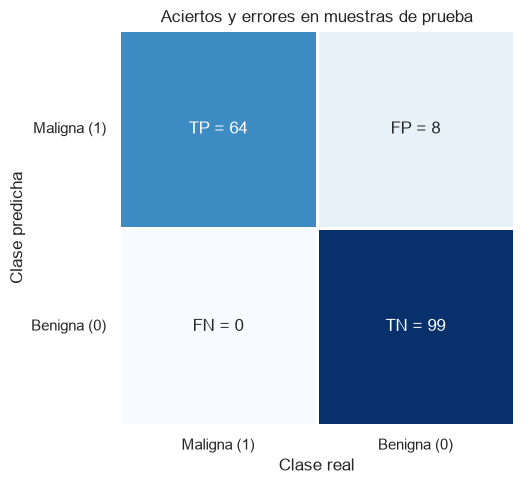

In [45]:
tp = int(((y_test == 1) & (y_pred == 1)).sum())
fp = int(((y_test == 0) & (y_pred == 1)).sum())
fn = int(((y_test == 1) & (y_pred == 0)).sum())
tn = int(((y_test == 0) & (y_pred == 0)).sum())

matrix = np.array([[tp, fp], [fn, tn]])
annotations = np.array([[f"TP = {tp}", f"FP = {fp}"],
                        [f"FN = {fn}", f"TN = {tn}"]])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matrix, annot=annotations, fmt="", cmap="Blues", cbar=False,
            square=True, linewidths=1,
            xticklabels=["Maligna (1)", "Benigna (0)"],
            yticklabels=["Maligna (1)", "Benigna (0)"], ax=ax)
ax.set(xlabel="Clase real", ylabel="Clase predicha",
       title="Aciertos y errores en muestras de prueba")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

#### ¿Cómo se leen TP, FP, FN y TN?

Las siglas están en inglés y combinan dos ideas:

- **P / N (positivo / negativo):** lo que **predijo el modelo**. Positivo significa
  maligna; negativo, benigna.
- **T / F (verdadero / falso):** si esa predicción **coincide o no con la clase real**.

Por ejemplo, **FP** significa «predijimos positivo, pero fue falso»: señalamos
como maligna una muestra que realmente es benigna.

| Casilla | Nombre | Cómo leerla |
| --- | --- | --- |
| TP | Verdadero positivo (*True Positive*) | Predijimos maligna y realmente es maligna. |
| FP | Falso positivo (*False Positive*) | Predijimos maligna, pero realmente es benigna. |
| FN | Falso negativo (*False Negative*) | Predijimos benigna, pero realmente es maligna. |
| TN | Verdadero negativo (*True Negative*) | Predijimos benigna y realmente es benigna. |

En nuestro orden `[[TP, FP], [FN, TN]]`, la fila superior reúne todas las muestras
**señaladas**: `TP + FP`. La columna izquierda reúne todas las muestras
**realmente malignas**: `TP + FN`. La diagonal contiene los aciertos: `TP + TN`.

### Accuracy, precisión y recall

Convertimos los conteos de la matriz en tres formas de resumir el resultado.
El **total** es la suma de las cuatro casillas: `TP + FP + FN + TN`.

| Métrica | Cálculo | Pregunta que responde |
| --- | --- | --- |
| Accuracy | `(TP + TN) / total` | ¿Qué proporción de muestras clasificamos bien? |
| Precisión | `TP / (TP + FP)` | ¿Cuánto acertamos entre las muestras señaladas? |
| Recall | `TP / (TP + FN)` | ¿Qué proporción de malignas detectamos? |

La selección ya se hizo por recall de validación. Ahora medimos el resultado final.

#### Sustituir las letras por los valores de nuestra matriz

En la matriz anterior tenemos **TP = 64**, **FP = 8**, **FN = 0** y **TN = 99**.
El total es `64 + 8 + 0 + 99 = 171` muestras. Multiplicamos cada proporción por 100
para expresarla como porcentaje:

| Métrica | Sustitución y cálculo | Resultado |
| --- | --- | --- |
| Accuracy | `(64 + 99) / 171 × 100 = 163 / 171 × 100` | **95,32%** |
| Precisión | `64 / (64 + 8) × 100 = 64 / 72 × 100` | **88,89%** |
| Recall | `64 / (64 + 0) × 100 = 64 / 64 × 100` | **100%** |

- **Accuracy:** clasificamos bien **163 de las 171 muestras**, contando malignas y benignas.
- **Precisión:** de las **72 muestras señaladas como malignas**, **64 realmente lo son**.
- **Recall:** de las **64 muestras realmente malignas**, **detectamos las 64**.

En nuestra matriz, precisión divide TP entre el total de la **fila superior** y
recall divide TP entre el total de la **columna izquierda**. Usan el mismo número
de malignas detectadas, pero responden preguntas distintas. Accuracy combina los
dos aciertos de la diagonal. Una accuracy alta puede ocultar que la clase minoritaria
se detecta poco.

Si no señalamos ninguna muestra, no podemos calcular precisión: no hay positivos
predichos que evaluar. `zero_division=np.nan` muestra ese caso como `NaN` («sin valor»).
La tabla convierte las tres métricas a porcentajes con `.mul(100).round(2)`.

In [46]:
metrics = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred), accuracy_score(y_test, baseline_pred)],
    "Precisión": [precision_score(y_test, y_pred, zero_division=np.nan),
                  precision_score(y_test, baseline_pred, zero_division=np.nan)],
    "Recall": [recall_score(y_test, y_pred), recall_score(y_test, baseline_pred)],
}, index=[type(best_model.named_steps["model"]).__name__, "Baseline: clase mayoritaria"])
metrics.mul(100).round(2).rename(columns=lambda column: f"{column} (%)")

,Accuracy (%),Precisión (%),Recall (%)
CalibratedClassifierCV,95.32,88.89,100.0
Baseline: clase mayoritaria,62.57,NaN,0.0


El **SVM RBF calibrado** detecta **64 de 64 malignas (100% de recall)**.
Señala 72 muestras y 64 son malignas: **88,89% de precisión**. Quedan
**0 malignas sin detectar** y **8 falsas alarmas**.
En la tabla, `CalibratedClassifierCV` es el clasificador que convierte los
puntajes de SVM en probabilidades.

La accuracy es **95,32%**, frente a **62,57%** del baseline. El baseline no detecta
ninguna maligna. La accuracy cuenta todos los aciertos; recall se concentra en
las malignas y precisión, en las muestras señaladas. Por eso leemos las tres juntas.

El recall de 100% describe **estas 64 malignas**: no garantiza detectar todas las
malignas futuras. Cada maligna adicional detectada o perdida cambiaría el recall
en aproximadamente **1,6 puntos porcentuales** en una prueba de ese tamaño.
No cambiamos el modelo ni el umbral a partir de estos resultados.

### Curva ROC: detección y falsas alarmas

**Ejemplo ficticio:** hay 100 muestras malignas y 200 benignas.
Detectamos 80 malignas y señalamos por error a 20 benignas:

- **Eje vertical:** 80/100 = **80% de malignas detectadas** (recall).
- **Eje horizontal:** 20/200 = **10% de falsas alarmas entre benignas**.

Ese resultado es el punto **(0,10; 0,80)**. Cada punto de la curva usa un umbral
distinto. Queremos acercarnos a la **esquina superior izquierda**: mucha detección
y pocas falsas alarmas.

**¿Cuándo usarla?** Para comparar detección y falsas alarmas. La diagonal gris
representa una ordenación al azar. **AUC** es el área bajo la curva: 1 indica
separación perfecta y 0,5, nivel aleatorio. No es un porcentaje de aciertos.

Un 10% de falsas alarmas entre 10.000 benignas son 1.000 muestras señaladas por
error. Para saber cuánto acertamos entre las señaladas, miramos precisión–recall.

Estas curvas usan probabilidades de prueba para evaluar; el umbral se compara en validación.

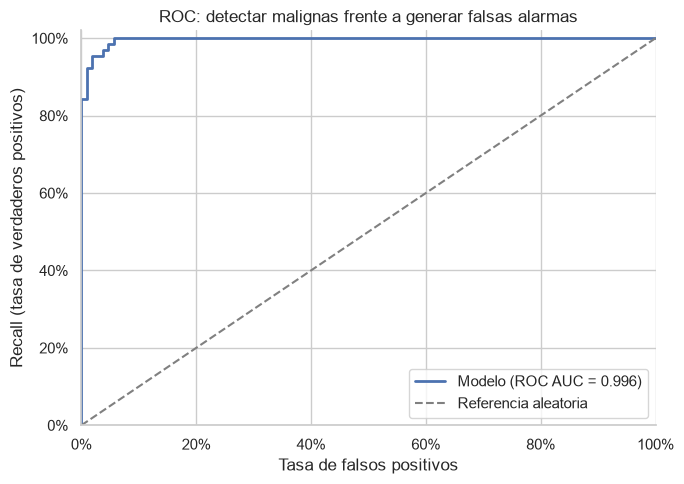

In [47]:
test_probability = best_model.predict_proba(X_test)[:, 1]
fpr, tpr, roc_thresholds = roc_curve(y_test, test_probability)
roc_auc = roc_auc_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr, tpr, label=f"Modelo (ROC AUC = {roc_auc:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Recall (tasa de verdaderos positivos)",
       title="ROC: detectar malignas frente a generar falsas alarmas",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.tight_layout()
plt.show()

### Curva precisión–recall: ¿a cuántas detectamos y cuánto acertamos?

**Ejemplo ficticio:** hay 100 muestras malignas. Señalamos a 160 muestras
y entre ellas hay 80 malignas:

- **Eje horizontal, recall:** detectamos 80/100 = **80% de las malignas**.
- **Eje vertical, precisión:** acertamos en 80/160 = **50% de las señaladas**.

Ese resultado es el punto **(0,80; 0,50)**. Cada punto usa un umbral distinto.
Queremos acercarnos a la **esquina superior derecha**: detectar muchas malignas
y acertar en muchas de las muestras señaladas.

**¿Cuándo usarla?** Cuando necesitamos valorar si detectar más malignas compensa
las falsas alarmas, especialmente si la clase maligna es poco frecuente.

La línea gris muestra la precisión esperada al elegir muestras al azar:
**37,4%** en esta prueba. **AP** (*average precision*, precisión promedio) resume
la curva; cuanto mayor, mejor. No es el porcentaje total de aciertos.

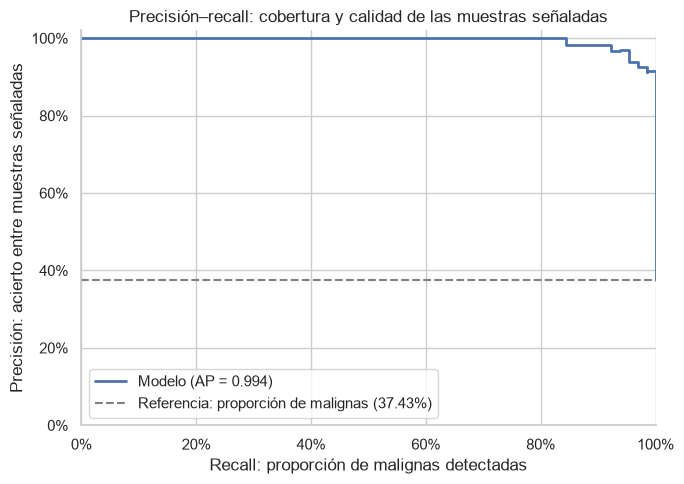

In [48]:
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test, test_probability)
average_precision = average_precision_score(y_test, test_probability)

fig, ax = plt.subplots(figsize=(7, 5))
ax.step(pr_recall, pr_precision, where="post", linewidth=2,
        label=f"Modelo (AP = {average_precision:.3f})")
ax.axhline(y_test.mean(), linestyle="--", color="gray",
           label=f"Referencia: proporción de malignas ({y_test.mean():.2%})")
ax.set(xlabel="Recall: proporción de malignas detectadas",
       ylabel="Precisión: acierto entre muestras señaladas",
       title="Precisión–recall: cobertura y calidad de las muestras señaladas",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.tight_layout()
plt.show()

## 6. Uso de los resultados

Tomamos una muestra de prueba para ver una predicción paso a paso.
Mostramos sus entradas; no es una nueva evaluación.

In [49]:
sample_index = X_test.index[0]
held_out_sample = X_test.loc[[sample_index]]
held_out_sample.T.rename(columns={sample_index: "Entrada real"})

,Entrada real
mean radius,14.530000
mean texture,19.340000
mean perimeter,94.250000
mean area,659.700000
mean smoothness,0.083880
mean compactness,0.078000
mean concavity,0.088170
mean concave points,0.029250
mean symmetry,0.147300
mean fractal dimension,0.057460


El pipeline prepara la fila y aplica el modelo elegido. `predict_proba()` devuelve las
probabilidades de las clases 0 y 1; `[0, 1]` elige la primera fila y la clase maligna.
Comparamos esa probabilidad con la clase predicha y la etiqueta real.

In [50]:
sample_probability = best_model.predict_proba(held_out_sample)[0, 1]
sample_prediction = best_model.predict(held_out_sample)[0]
print(f"Muestra (índice): {sample_index}")
print(f"Probabilidad estimada de malignidad: {sample_probability:.1%}")
print(f"Clase predicha: {sample_prediction}; clase real: {y_test.loc[sample_index]}")

Muestra (índice): 448
Probabilidad estimada de malignidad: 27.9%
Clase predicha: False; clase real: False


Para esta muestra, la probabilidad estimada de malignidad es **27,9%** y la clase
predicha es **False**, que coincide con la real: benigna. Esa cifra no garantiza el diagnóstico.

El SVM RBF calibrado detecta **64 de 64 malignas** en prueba y señala por error
**8 benignas**. La red y XGBoost aprendieron otras formas de separar las clases;
el resultado depende de las muestras y de las configuraciones que se muestrearon.
Es un ejercicio educativo, no un sistema de diagnóstico.

## 7. Mismo análisis con la configuración 13: red neuronal

Repetimos el análisis anterior con la **configuración 13**, una red neuronal
con una capa oculta de **16 neuronas**. Recuperamos sus parámetros por su número
original en la búsqueda (`13 - 1`), no por su posición en la tabla ordenada.
Clonamos el pipeline y lo ajustamos con el mismo entrenamiento; el escalado
se aprende dentro de cada ajuste.

Esta comparación complementa los resultados de la configuración 14. La selección
original por recall de validación sigue siendo la SVM. Como ya observamos prueba,
esta evaluación adicional es exploratoria y no sirve como una nueva selección
independiente del modelo. Usamos el mismo reparto y conservamos el umbral **0,50**.


In [52]:
from sklearn.base import clone

config_13_params = search.cv_results_["params"][13 - 1]
model_13 = clone(pipeline).set_params(**{
    name: clone(value) if hasattr(value, "get_params") else value
    for name, value in config_13_params.items()
})
model_13.fit(X_train, y_train)
print("Configuración 13:", model_13.named_steps["model"])
display(cv_percentages.loc[[13]])


Configuración 13: MLPClassifier(alpha=0.001, hidden_layer_sizes=(16,), max_iter=2000,
              random_state=42)


,Modelo,Kernel,C,Gamma,Capas,Alpha,Profundidad,Árboles,Recall medio (%),Precisión media (%),Balanced accuracy (%),F1 weighted (0–1),Desviación (p. p.)
Configuración,,,,,,,,,,,,,
13,MLPClassifier,—,—,—,"(16,)",0.001,—,—,96.62,96.77,97.31,0.974946,0.06


In [53]:
best_model_13 = model_13


### Umbral: comparar las mismas cinco opciones

Obtenemos probabilidades fuera de muestra dentro de entrenamiento con los mismos
cinco folds. Cada fila se predice con un pipeline que no la usó para entrenar.
Contamos señaladas, falsos negativos y falsos positivos para cada umbral.
Precisión y recall se muestran en porcentaje. Conservamos **0,50** para prueba;
no elegimos un umbral a partir de los resultados de prueba.


In [54]:
validation_probability_13 = cross_val_predict(
    best_model_13, X_train, y_train, cv=cv, method="predict_proba", n_jobs=2,
)[:, 1]

threshold_rows_13 = []
for threshold in [0.20, 0.40, 0.50, 0.60, 0.80]:
    threshold_prediction_13 = validation_probability_13 >= threshold
    fn_13 = int(((y_train == 1) & (threshold_prediction_13 == 0)).sum())
    fp_13 = int(((y_train == 0) & (threshold_prediction_13 == 1)).sum())
    threshold_rows_13.append({
        "Umbral": threshold,
        "Señaladas": int(threshold_prediction_13.sum()),
        "FN": fn_13,
        "FP": fp_13,
        "Precisión": precision_score(y_train, threshold_prediction_13, zero_division=np.nan),
        "Recall": recall_score(y_train, threshold_prediction_13),
    })

threshold_summary_13 = pd.DataFrame(threshold_rows_13).set_index("Umbral")
threshold_summary_13[["Precisión", "Recall"]] = threshold_summary_13[["Precisión", "Recall"]].mul(100).round(2)
threshold_summary_13 = threshold_summary_13.rename(columns={
    "Precisión": "Precisión (%)", "Recall": "Recall (%)",
})
threshold_summary_13

,Señaladas,FN,FP,Precisión (%),Recall (%)
Umbral,,,,,
0.2,157,3,12,92.36,97.97
0.4,153,4,9,94.12,97.30
0.5,148,5,5,96.62,96.62
0.6,145,7,4,97.24,95.27
0.8,140,10,2,98.57,93.24


### Evaluación en las mismas muestras de prueba

Predecimos con la red entrenada y mostramos la misma matriz: filas de clase
predicha y columnas de clase real. TP son malignas detectadas; FN, malignas
clasificadas como benignas; FP, benignas señaladas; TN, benignas bien clasificadas.


In [55]:
y_pred_13 = model_13.predict(X_test)


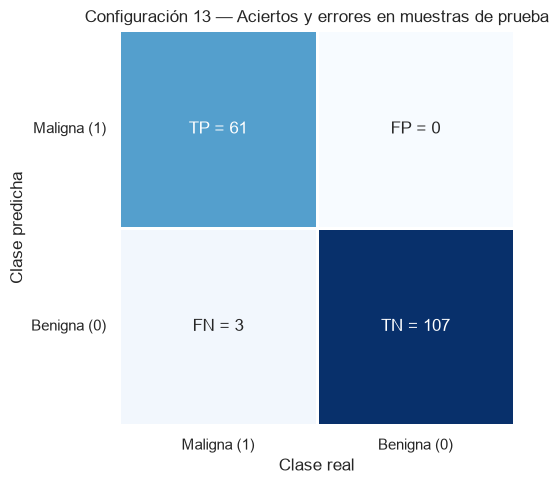

In [56]:
tp_13 = int(((y_test == 1) & (y_pred_13 == 1)).sum())
fp_13 = int(((y_test == 0) & (y_pred_13 == 1)).sum())
fn_13 = int(((y_test == 1) & (y_pred_13 == 0)).sum())
tn_13 = int(((y_test == 0) & (y_pred_13 == 0)).sum())

matrix_13 = np.array([[tp_13, fp_13], [fn_13, tn_13]])
annotations_13 = np.array([[f"TP = {tp_13}", f"FP = {fp_13}"],
                        [f"FN = {fn_13}", f"TN = {tn_13}"]])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matrix_13, annot=annotations_13, fmt="", cmap="Blues", cbar=False,
            square=True, linewidths=1,
            xticklabels=["Maligna (1)", "Benigna (0)"],
            yticklabels=["Maligna (1)", "Benigna (0)"], ax=ax)
ax.set(xlabel="Clase real", ylabel="Clase predicha",
       title="Configuración 13 — Aciertos y errores en muestras de prueba")
ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.show()

### Accuracy, precisión y recall

Calculamos las mismas métricas y añadimos la configuración 14 y el baseline
para comparar sobre exactamente las mismas muestras. Accuracy resume todos
los aciertos; precisión mide el acierto entre señaladas y recall, la proporción
de malignas detectadas. Un valor sin positivos predichos aparece como `NaN`.


In [57]:
comparison_predictions = {
    "Configuración 13: red neuronal": y_pred_13,
    "Configuración 14: SVM RBF": y_pred,
    "Baseline: clase mayoritaria": baseline_pred,
}
metrics_13 = pd.DataFrame({
    name: {
        "Accuracy (%)": accuracy_score(y_test, prediction) * 100,
        "Precisión (%)": precision_score(y_test, prediction, zero_division=np.nan) * 100,
        "Recall (%)": recall_score(y_test, prediction) * 100,
    }
    for name, prediction in comparison_predictions.items()
}).T
metrics_13.round(2)


,Accuracy (%),Precisión (%),Recall (%)
Configuración 13: red neuronal,98.25,100.00,95.31
Configuración 14: SVM RBF,95.32,88.89,100.00
Baseline: clase mayoritaria,62.57,NaN,0.00


In [58]:
print(f"Red neuronal: detecta {tp_13} de {tp_13 + fn_13} malignas.")
print(f"Señala {tp_13 + fp_13} muestras: {tp_13} malignas y {fp_13} benignas.")
print(f"Quedan {fn_13} malignas sin detectar; clasifica bien {tn_13} benignas.")
print(f"Accuracy = ({tp_13} + {tn_13}) / {len(y_test)} = {accuracy_score(y_test, y_pred_13):.2%}")
print(f"Precisión = {tp_13} / {tp_13 + fp_13} = {precision_score(y_test, y_pred_13, zero_division=np.nan):.2%}")
print(f"Recall = {tp_13} / {tp_13 + fn_13} = {recall_score(y_test, y_pred_13):.2%}")


Red neuronal: detecta 61 de 64 malignas.
Señala 61 muestras: 61 malignas y 0 benignas.
Quedan 3 malignas sin detectar; clasifica bien 107 benignas.
Accuracy = (61 + 107) / 171 = 98.25%
Precisión = 61 / 61 = 100.00%
Recall = 61 / 64 = 95.31%


### Curva ROC: detección y falsas alarmas

Usamos las probabilidades de malignidad de la red. Cada punto corresponde a
un umbral: el eje vertical muestra recall y el horizontal, falsas alarmas entre
benignas. ROC AUC resume la ordenación de las muestras a lo largo de los umbrales;
no es el porcentaje de aciertos con umbral 0,50.


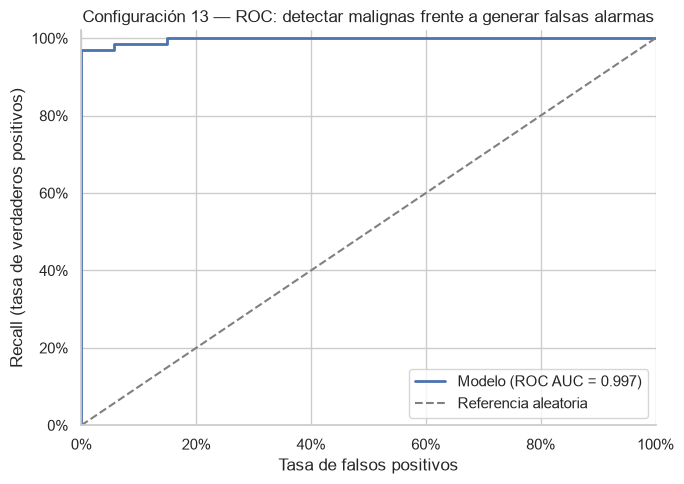

In [59]:
test_probability_13 = best_model_13.predict_proba(X_test)[:, 1]
fpr_13, tpr_13, roc_thresholds_13 = roc_curve(y_test, test_probability_13)
roc_auc_13 = roc_auc_score(y_test, test_probability_13)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(fpr_13, tpr_13, label=f"Modelo (ROC AUC = {roc_auc_13:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Referencia aleatoria")
ax.set(xlabel="Tasa de falsos positivos", ylabel="Recall (tasa de verdaderos positivos)",
       title="Configuración 13 — ROC: detectar malignas frente a generar falsas alarmas",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower right")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.tight_layout()
plt.show()

### Curva precisión–recall

El eje horizontal indica qué proporción de malignas detectamos y el vertical,
cuánto acertamos entre las muestras señaladas. AP resume esta relación a lo
largo de los umbrales. La línea gris muestra la proporción de malignas en prueba;
comparamos con esa misma referencia usada para la configuración 14.


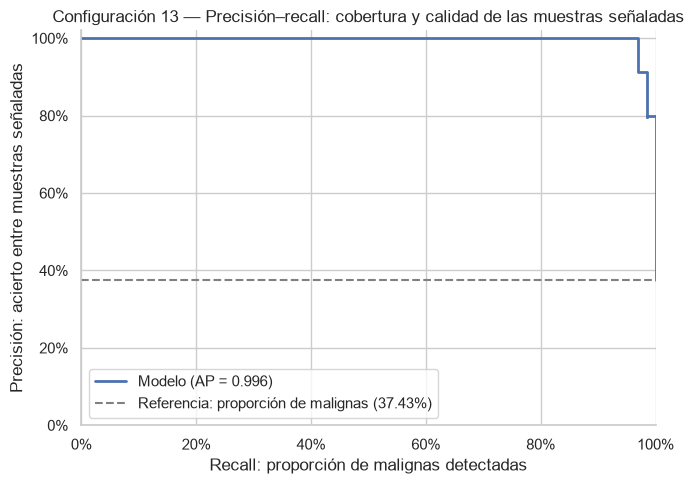

In [60]:
pr_precision_13, pr_recall_13, pr_thresholds_13 = precision_recall_curve(y_test, test_probability_13)
average_precision_13 = average_precision_score(y_test, test_probability_13)

fig, ax = plt.subplots(figsize=(7, 5))
ax.step(pr_recall_13, pr_precision_13, where="post", linewidth=2,
        label=f"Modelo (AP = {average_precision_13:.3f})")
ax.axhline(y_test.mean(), linestyle="--", color="gray",
           label=f"Referencia: proporción de malignas ({y_test.mean():.2%})")
ax.set(xlabel="Recall: proporción de malignas detectadas",
       ylabel="Precisión: acierto entre muestras señaladas",
       title="Configuración 13 — Precisión–recall: cobertura y calidad de las muestras señaladas",
       xlim=(0, 1), ylim=(0, 1.02))
ax.legend(loc="lower left")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
plt.tight_layout()
plt.show()

### Uso de los resultados: la misma muestra

Reutilizamos `held_out_sample`, la misma fila del ejemplo de SVM, para comparar
su probabilidad y decisión con la clase real. La probabilidad corresponde a la
clase maligna; `predict()` aplica la decisión habitual con umbral 0,50.


In [61]:
held_out_sample.T.rename(columns={sample_index: "Entrada real"})


,Entrada real
mean radius,14.530000
mean texture,19.340000
mean perimeter,94.250000
mean area,659.700000
mean smoothness,0.083880
mean compactness,0.078000
mean concavity,0.088170
mean concave points,0.029250
mean symmetry,0.147300
mean fractal dimension,0.057460


In [62]:
sample_probability_13 = best_model_13.predict_proba(held_out_sample)[0, 1]
sample_prediction_13 = best_model_13.predict(held_out_sample)[0]
print(f"Muestra (índice): {sample_index}")
print(f"Probabilidad estimada de malignidad: {sample_probability_13:.1%}")
print(f"Clase predicha: {sample_prediction_13}; clase real: {y_test.loc[sample_index]}")

Muestra (índice): 448
Probabilidad estimada de malignidad: 12.3%
Clase predicha: False; clase real: False


Los conteos y métricas anteriores describen esta prueba. Comparar ambos modelos
permite ver el intercambio entre malignas detectadas y falsas alarmas, pero no
garantiza el mismo resultado en futuras muestras. Es un ejercicio educativo,
no un sistema de diagnóstico.


## Referencias

Documentación oficial para consultar los conceptos y las herramientas de la sesión.

### Datos y exploración

- [Breast Cancer Wisconsin (Diagnostic), UCI](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic): origen, mediciones y descripción de la fuente.
- [load_breast_cancer](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html): versión incluida y codificación de etiquetas.
- [pandas: primeros pasos](https://pandas.pydata.org/docs/getting_started/intro_tutorials/index.html), [groupby](https://pandas.pydata.org/docs/user_guide/groupby.html) y [correlación](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

### Preparación

- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) y [evitar fuga de información](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), [StratifiedKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html) y [cross_val_predict](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html).

### Modelos y validación

- [DummyClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html).
- [CalibratedClassifierCV](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibratedClassifierCV.html).
- [Máquinas de vectores de soporte](https://scikit-learn.org/stable/modules/svm.html) y [SVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html).
- [Redes neuronales supervisadas](https://scikit-learn.org/stable/modules/neural_networks_supervised.html) y [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html).
- [Introducción a los árboles con boosting](https://xgboost.readthedocs.io/en/stable/tutorials/model.html), [parámetros de XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html) y [XGBClassifier](https://xgboost.readthedocs.io/en/stable/python/python_api.html#xgboost.XGBClassifier).

### Evaluación

- [Glass Box Medicine: explicación general de la matriz de confusión](https://glassboxmedicine.com/2019/02/17/measuring-performance-the-confusion-matrix/).

- [Recall](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html), [precisión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html) y [matriz de confusión](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).
- [ROC AUC](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html), [precisión–recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html) y [average precision](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.average_precision_score.html).
- [Umbrales de decisión](https://scikit-learn.org/stable/modules/classification_threshold.html) y [calibración de probabilidades](https://scikit-learn.org/stable/modules/calibration.html).